# In-context learning (ICL) across symmetry groups: a comparative benchmark

**Question.** How do the symmetry group 𝔊 and the domain Ω built into an architecture (Bronstein et al., *Geometric Deep Learning*, Table "5G") shape its **in-context learning**?

**Benchmarks** (from the two reference papers):
* **Lu et al., *Asymptotic theory of in-context learning by linear attention*:** in-context linear regression `y = <w,x> + ε`, `x ~ N(0, I/d)`, `w ~ N(0, I)`, `ε ~ N(0, ρ)`. Pretraining **task diversity** `k` (finite pool of `w`) controls the move from memorization (**IDG**, in-distribution generalization) to genuine **ICL** (novel `w`). Baselines: Bayes ridge (optimal for ICL) and dMMSE (optimal on the finite pool). Their reduced linear-attention model `ŷ = <Γ, H_Z>` is included as a model.
* **Schug et al., *Attention as a Hypernetwork*:** fuzzy-logic functions in disjunctive normal form (L=4 variables, K=2 terms), with a **compositional split**: held-out *combinations* of seen terms (OOD R²). Their **HYLA** attention (RMSHead normalization over heads plus a nonlinear value network) is included.

**Architectures ↔ rows of the GDL table.** Every model maps a token sequence `[(x_1,y_1),…,(x_ℓ,y_ℓ),(x_q,0)]` to `ŷ_q`. Each token is `[x, y, query-flag]`.

| Model | GDL row | Domain Ω | Built-in symmetry 𝔊 (on the context) |
|---|---|---|---|
| `MLP` | none (baseline) | fixed-size vector | trivial {e} |
| `LSTM` | LSTM | 1D grid | time warping (gated recurrence, order-dependent) |
| `CNN-1D` | CNN | 1D grid (circular) | translation ℤ_T (cyclic shifts) |
| `GNN-kNN` | GNN | sparse kNN graph in x-space | permutation Σ_n, local aggregation |
| `DeepSets` | Deep Sets | set | permutation Σ_n (sum/mean pooling) |
| `LinAttn-Γ` | Transformer (Lu et al. reduced) | set / complete graph | Σ_n (+ exact under duplication) |
| `LinTF` | Transformer, linear attention | complete graph | Σ_n |
| `SoftTF` | Transformer, softmax | complete graph | Σ_n |
| `HYLA-TF` | Transformer, HYLA (Schug et al.) | complete graph | Σ_n |
| `SoftTF+PE` | Transformer + positional encoding | sequence | Σ_n **broken** by PE (ablation) |
| `Gram-O(d)` | Spherical / rotation-equivariant analog | complete graph, invariant edge features `<x_i,x_j>` | Σ_n × **O(d)** (exactly invariant to rotating x-space) |

*Spherical CNNs (SO(3) on S²) and Mesh/gauge CNNs have no direct analog for token-set ICL. The rotation row is represented by its group-theoretic content instead: the linear-regression task is invariant to `x → Rx, w → Rw` for any `R ∈ O(d)`. `Gram-O(d)` is an invariant message-passing network (SchNet/EGNN-style continuous filters on Gram entries) that has this symmetry exactly. Gauge symmetry needs a fiber bundle and is left out.*

**Experiments**
1. **E1 — ICL vs context length** (train ℓ ∈ [ℓ_min, ℓ_max], test up to 2·ℓ_max = length extrapolation), plus training curves (sample efficiency).
2. **E2 — Task diversity** `k` → memorization-to-ICL transition (ICL vs IDG error), as in Lu et al.
3. **E3 — Symmetry probes:** apply group actions at test time (context permutation, cyclic shift, O(d) rotation, coordinate permutation, y-sign flip, time-warp by token duplication, variable negation for fuzzy logic). Measure the **equivariance violation** `Δ = E[(f(gZ) − ρ(g)f(Z))²]/Var(y)` and the error after the transformation.
4. **E4 — Symmetry *mismatch*:** a drifting-task regression in which order matters (`w` drifts along the context). Permutation-invariant models *should* fail here, which shows that symmetry is a prior that helps only when it matches the task.
5. **E5 — Compositional ICL (fuzzy logic):** OOD R² vs fraction of held-out term combinations, and vs context length. The fuzzy task is **not** O(d)-symmetric (inputs live in a cube), so it is a second mismatch test for `Gram-O(d)`.

**Runs locally (no Colab, no internet needed while running).** The notebook detects the hardware itself: **NVIDIA GPU (CUDA)** on Windows/Linux, **Apple GPU (MPS)** or **CPU** on a Mac (on MPS the `LSTM` is trained on the CPU because of an MPS memory leak; any model that runs out of memory is retried on the CPU automatically). On a Mac it times a few training steps on MPS and on CPU and picks the faster one, because these models are small and the CPU often wins. To force a device, set `DEVICE_PREF` in the setup cell.

**Setup (once):** Python ≥ 3.9, then in a terminal:
* **Mac (Apple Silicon):** `pip install torch numpy matplotlib pandas jupyter` (the PyPI `torch` for macOS includes MPS support).
* **Windows with an NVIDIA GPU:** PyPI's Windows `torch` is CPU-only. Install the CUDA build from the selector at pytorch.org, e.g. `pip install torch --index-url https://download.pytorch.org/whl/cu126` (pick the CUDA version the selector shows), then `pip install numpy matplotlib pandas jupyter`. Check with `python -c "import torch; print(torch.cuda.is_available())"`, which should print `True`.

**Approximate runtime** of `MODE='QUICK'`: about 1 h on a recent NVIDIA GPU, about 2–4 h on an Apple-Silicon Mac. `MODE='FULL'` (3 seeds, 10k steps, more k / holdout values) takes about 6–10 h on a GPU. `MODE='SMOKE'` takes 1–3 min and only checks that everything runs. Results are written to `./results/` next to the notebook.

In [1]:
# ==== Setup & configuration ====
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # Mac: run any op MPS lacks on the CPU
import math, time, json, itertools, random, warnings, gc
warnings.filterwarnings('ignore', message='Mean of empty slice')
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

DEVICE_PREF = 'cpu'    # 'auto' | 'cuda' | 'mps' | 'cpu'
HAS_MPS = getattr(torch.backends, 'mps', None) is not None and torch.backends.mps.is_available()
if DEVICE_PREF != 'auto':
    DEVICE = DEVICE_PREF
elif torch.cuda.is_available():
    DEVICE = 'cuda'
else:
    DEVICE = 'cpu'          # on a Mac, MPS vs CPU is decided by a short benchmark after the models are defined
print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available(), '| MPS:', HAS_MPS, '| device (provisional):', DEVICE)
if DEVICE == 'cuda': print('GPU:', torch.cuda.get_device_name(0))

MODE = 'FULL'          # 'SMOKE' | 'QUICK' | 'FULL'

CFG_ALL = {
    'SMOKE': dict(steps=40,   batch=32,  seeds=[0],       eval_n=256,  k_list=[8, None],
                  fuzzy_holdout=[0.5],              width=32),
    'QUICK': dict(steps=5000, batch=128, seeds=[0],       eval_n=2048, k_list=[4, 16, 64, 256, None],
                  fuzzy_holdout=[0.3, 0.7],         width=64),
    'FULL':  dict(steps=10000, batch=128, seeds=[0, 1, 2], eval_n=4096, k_list=[4, 16, 64, 256, 1024, None],
                  fuzzy_holdout=[0.1, 0.3, 0.5, 0.7, 0.9], width=64),
}
CFG = CFG_ALL[MODE]

# Linear-regression task (Lu et al.)
D_LR, RHO = 8, 0.25                 # token dim d, noise variance rho
LR_LMIN, LR_LMAX = 4, 32            # training context lengths
LR_TEST_LENS = [2, 4, 8, 12, 16, 24, 32, 48, 64]
# Fuzzy-logic task (Schug et al.)
FZ_L, FZ_K = 4, 2
FZ_LMIN, FZ_LMAX = 8, 32
FZ_TEST_LENS = [4, 8, 16, 24, 32, 48]
# Drift (symmetry-mismatch) task
DR_LMIN, DR_LMAX, DR_TEST_L = 16, 40, 32

LR = 1e-3
OUT = 'results'; os.makedirs(OUT, exist_ok=True)

# Which models to run (comment out to save time)
MODEL_NAMES = ['MLP', 'LSTM', 'CNN-1D', 'GNN-kNN', 'DeepSets', 'LinAttn-Γ',
               'LinTF', 'SoftTF', 'HYLA-TF', 'SoftTF+PE', 'Gram-O(d)']

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
    if HAS_MPS: torch.mps.manual_seed(s)

torch 2.15.0 | CUDA: False | MPS: True | device (provisional): cpu


## Tasks
Tokens are `[x (d), y (1), flag (1)]`. The query token has `y=0, flag=1` and is placed last (transforms such as cyclic shift can move it; every model finds the query by its flag).

In [2]:
def make_tokens(X, Y, xq):
    """X:(B,l,d) Y:(B,l) xq:(B,d) -> Z:(B,l+1,d+2)"""
    B, l, d = X.shape
    ctx = torch.cat([X, Y.unsqueeze(-1), torch.zeros(B, l, 1, device=X.device)], -1)
    q = torch.cat([xq, torch.zeros(B, 1, device=X.device), torch.ones(B, 1, device=X.device)], -1)
    return torch.cat([ctx, q.unsqueeze(1)], 1)

class LinRegTask:
    """In-context linear regression with task diversity k (k=None -> infinite)."""
    def __init__(self, d=D_LR, rho=RHO, k=None, seed=0):
        self.d, self.rho, self.k = d, rho, k
        g = torch.Generator().manual_seed(1000 + seed)
        self.pool = None if k is None else torch.randn(k, d, generator=g).to(DEVICE)
    def sample_w(self, B, split):
        if split == 'train' and self.pool is not None:
            return self.pool[torch.randint(0, self.k, (B,), device=DEVICE)]
        return torch.randn(B, self.d, device=DEVICE)  # 'novel' (ICL) or infinite diversity
    def sample(self, B, l, split='train'):
        d = self.d
        w = self.sample_w(B, split)
        X = torch.randn(B, l + 1, d, device=DEVICE) / math.sqrt(d)
        Y = (X @ w.unsqueeze(-1)).squeeze(-1) + math.sqrt(self.rho) * torch.randn(B, l + 1, device=DEVICE)
        b = dict(X=X[:, :l], Y=Y[:, :l], xq=X[:, l], yq=Y[:, l], w=w)
        b['Z'] = make_tokens(b['X'], b['Y'], b['xq'])
        return b

class DriftTask:
    """Order-dependent ICL: w drifts linearly from w_a (t=0) to w_b (query, t=l+1)."""
    def __init__(self, d=D_LR, rho=RHO):
        self.d, self.rho = d, rho
    def sample(self, B, l, split='train'):
        d = self.d
        wa, wb = torch.randn(B, d, device=DEVICE), torch.randn(B, d, device=DEVICE)
        s = torch.arange(1, l + 2, device=DEVICE).float() / (l + 1)           # (l+1,)
        W = (1 - s)[None, :, None] * wa[:, None] + s[None, :, None] * wb[:, None]
        X = torch.randn(B, l + 1, d, device=DEVICE) / math.sqrt(d)
        Y = (X * W).sum(-1) + math.sqrt(self.rho) * torch.randn(B, l + 1, device=DEVICE)
        b = dict(X=X[:, :l], Y=Y[:, :l], xq=X[:, l], yq=Y[:, l], s=s)
        b['Z'] = make_tokens(b['X'], b['Y'], b['xq'])
        return b

class FuzzyTask:
    """Fuzzy-logic DNF functions (Schug et al.): K terms out of 2^L negation patterns."""
    def __init__(self, L=FZ_L, K=FZ_K, holdout=0.5, seed=0):
        self.L, self.K = L, K
        combos = list(itertools.combinations(range(2 ** L), K))
        rng = np.random.RandomState(2000 + seed); rng.shuffle(combos)
        n_ood = int(round(holdout * len(combos)))
        self.ood = torch.tensor(combos[:n_ood], device=DEVICE)
        self.train = torch.tensor(combos[n_ood:], device=DEVICE)
        self.all = torch.tensor(combos, device=DEVICE)
        self.neg = torch.tensor([[(t >> j) & 1 for j in range(L)] for t in range(2 ** L)],
                                device=DEVICE).float()            # (2^L, L) negation masks
    def f(self, X, terms):
        """X:(B,n,L) terms:(B,K) -> (B,n)"""
        neg = self.neg[terms]                                     # (B,K,L)
        lit = X[:, None] * (1 - neg[:, :, None]) + (1 - X[:, None]) * neg[:, :, None]  # (B,K,n,L)
        return lit.min(-1).values.max(1).values
    def sample(self, B, l, split='train'):
        S = {'train': self.train, 'ood': self.ood, 'all': self.all}[split]
        terms = S[torch.randint(0, len(S), (B,), device=DEVICE)]
        X = torch.rand(B, l + 1, self.L, device=DEVICE)
        Y = self.f(X, terms)
        b = dict(X=X[:, :l], Y=Y[:, :l], xq=X[:, l], yq=Y[:, l], terms=terms)
        b['Z'] = make_tokens(b['X'], b['Y'], b['xq'])
        return b

## Baselines (Bayes-optimal estimators)

In [3]:
@torch.no_grad()
def ridge_pred(b, rho=RHO):
    """Posterior mean for prior w~N(0,I), noise var rho (optimal ICL estimator)."""
    X, Y = b['X'], b['Y']; d = X.shape[-1]
    A = X.transpose(1, 2) @ X + rho * torch.eye(d, device=X.device)
    w = torch.linalg.solve(A, (X.transpose(1, 2) @ Y.unsqueeze(-1))).squeeze(-1)
    return (w * b['xq']).sum(-1)

@torch.no_grad()
def dmmse_pred(b, pool, rho=RHO):
    """Posterior mean when w is uniform over a finite pool (optimal IDG estimator)."""
    X, Y = b['X'], b['Y']
    R = Y[:, None, :] - torch.einsum('bld,kd->bkl', X, pool)
    logp = -(R ** 2).sum(-1) / (2 * rho)
    p = torch.softmax(logp, -1)
    return (p * (b['xq'] @ pool.T)).sum(-1)

@torch.no_grad()
def drift_oracle_pred(b, rho=RHO):
    """Bayes oracle that knows the drift model: ridge on 2d features [(1-s)x, s x]."""
    X, Y, s = b['X'], b['Y'], b['s']; l = X.shape[1]; d = X.shape[-1]
    Phi = torch.cat([(1 - s[:l])[None, :, None] * X, s[:l][None, :, None] * X], -1)
    A = Phi.transpose(1, 2) @ Phi + rho * torch.eye(2 * d, device=X.device)
    th = torch.linalg.solve(A, Phi.transpose(1, 2) @ Y.unsqueeze(-1)).squeeze(-1)
    return (th[:, d:] * b['xq']).sum(-1)

@torch.no_grad()
def fuzzy_bayes_pred(b, task, which='all', sigma=0.05):
    """Posterior-mean predictor over a discrete set of DNF functions (all combos or train combos)."""
    S = task.all if which == 'all' else task.train
    B = b['X'].shape[0]; preds = []
    Xall = torch.cat([b['X'], b['xq'][:, None]], 1)
    logp = []
    for j in range(len(S)):
        fx = task.f(Xall, S[j].expand(B, -1))
        logp.append(-((fx[:, :-1] - b['Y']) ** 2).sum(-1) / (2 * sigma ** 2)); preds.append(fx[:, -1])
    p = torch.softmax(torch.stack(logp, -1), -1)
    return (p * torch.stack(preds, -1)).sum(-1)

## Architectures
Every model has `forward(Z) -> ŷ_q` (shape `(B,)`) and finds the query token by its flag (last channel).

In [4]:
def mlp(i, h, o, n=2, act=nn.GELU):
    layers, dim = [], i
    for _ in range(n - 1):
        layers += [nn.Linear(dim, h), act()]; dim = h
    layers.append(nn.Linear(dim, o))
    return nn.Sequential(*layers)

def gather_q(H, Z):
    idx = Z[..., -1].argmax(1)
    return H[torch.arange(H.shape[0], device=H.device), idx]

def ctx_mask(Z):
    return (1 - Z[..., -1]).unsqueeze(-1)     # 1 for context tokens, 0 for query

class MLPModel(nn.Module):
    """No symmetry: flattened, front-padded context of fixed max length."""
    def __init__(self, D, T_max, h=256):
        super().__init__(); self.T_max = T_max
        self.net = mlp(T_max * (D + 1), h, 1, 3)
    def forward(self, Z):
        B, T, D = Z.shape
        if T > self.T_max:
            return torch.full((B,), float('nan'), device=Z.device)
        Zp = torch.cat([Z, torch.ones(B, T, 1, device=Z.device)], -1)
        pad = torch.zeros(B, self.T_max - T, D + 1, device=Z.device)
        return self.net(torch.cat([pad, Zp], 1).flatten(1)).squeeze(-1)

class LSTMModel(nn.Module):
    """Gated recurrence: time-warping-invariant family (Tallec & Ollivier), order-dependent."""
    def __init__(self, D, h=128, layers=2):
        super().__init__()
        self.emb = nn.Linear(D, h); self.rnn = nn.LSTM(h, h, layers, batch_first=True); self.out = nn.Linear(h, 1)
    def forward(self, Z):
        H, _ = self.rnn(self.emb(Z))
        return self.out(gather_q(H, Z)).squeeze(-1)

class CNN1D(nn.Module):
    """Translation-equivariant (circular padding) dilated residual CNN over token positions."""
    def __init__(self, D, h=64, dilations=(1, 2, 4, 8, 1, 2, 4, 8)):
        super().__init__()
        self.emb = nn.Linear(D, h)
        self.dil = dilations
        self.convs = nn.ModuleList([nn.Conv1d(h, h, 3, dilation=dl) for dl in dilations])
        self.mixes = nn.ModuleList([nn.Conv1d(h, h, 1) for _ in dilations])
        self.norms = nn.ModuleList([nn.LayerNorm(h) for _ in dilations])
        self.out = nn.Linear(h, 1)
    def forward(self, Z):
        H = self.emb(Z)
        T = Z.shape[1]
        for conv, mix, ln, dl in zip(self.convs, self.mixes, self.norms, self.dil):
            idx = torch.arange(-dl, T + dl, device=Z.device) % T          # circular padding (any T)
            u = ln(H)[:, idx].transpose(1, 2)
            H = H + mix(F.gelu(conv(u))).transpose(1, 2)
        return self.out(gather_q(H, Z)).squeeze(-1)

class GNNkNN(nn.Module):
    """Permutation-equivariant message passing on a sparse kNN graph built in x-space."""
    def __init__(self, D, d, h=64, layers=3, k=8):
        super().__init__(); self.d, self.k = d, k
        self.emb = nn.Linear(D, h)
        self.msg = nn.ModuleList([mlp(2 * h + d, h, h, 2) for _ in range(layers)])
        self.upd = nn.ModuleList([mlp(2 * h, h, h, 2) for _ in range(layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(h) for _ in range(layers)])
        self.out = nn.Linear(h, 1)
    def forward(self, Z):
        B, T, _ = Z.shape; x = Z[..., :self.d]
        dist = torch.cdist(x, x) + torch.eye(T, device=Z.device) * 1e9
        k = min(self.k, T - 1)
        idx = dist.topk(k, largest=False).indices                     # (B,T,k)
        bi = torch.arange(B, device=Z.device)[:, None, None]
        rel = x[bi, idx] - x[:, :, None]                               # (B,T,k,d)
        H = self.emb(Z)
        for msg, upd, ln in zip(self.msg, self.upd, self.norms):
            Hn = ln(H)
            m = msg(torch.cat([Hn[:, :, None].expand(-1, -1, k, -1), Hn[bi, idx], rel], -1)).mean(2)
            H = H + upd(torch.cat([Hn, m], -1))
        return self.out(gather_q(H, Z)).squeeze(-1)

class DeepSets(nn.Module):
    """rho( mean_i phi(x_i, y_i), x_q ): permutation-invariant over the context set."""
    def __init__(self, D, d, h=128):
        super().__init__(); self.d = d
        self.phi = mlp(d + 1, h, h, 3); self.rho = mlp(h + d, h, 1, 3)
    def forward(self, Z):
        m = ctx_mask(Z)
        pooled = (self.phi(Z[..., :self.d + 1]) * m).sum(1) / m.sum(1)
        xq = gather_q(Z, Z)[..., :self.d]
        return self.rho(torch.cat([pooled, xq], -1)).squeeze(-1)

class LinAttnGamma(nn.Module):
    """Lu et al. reduced linear attention: y_hat = <Gamma, H_Z>,
    H_Z = [ x_q (d/l) sum y_i x_i^T ,  x_q (1/l) sum y_i^2 ]."""
    def __init__(self, D, d):
        super().__init__(); self.d = d
        self.G = nn.Parameter(torch.zeros(d, d + 1))
    def forward(self, Z):
        d = self.d; m = ctx_mask(Z); l = m.sum(1)
        x, y = Z[..., :d], Z[..., d:d + 1]
        s1 = d * (m * y * x).sum(1) / l                       # (B,d)
        s2 = (m * y ** 2).sum(1) / l                          # (B,1)
        xq = gather_q(Z, Z)[..., :d]
        return (xq * (s1 @ self.G[:, :d].T)).sum(-1) + (xq @ self.G[:, d]) * s2.squeeze(-1)

class Attention(nn.Module):
    def __init__(self, h, heads, kind):
        super().__init__(); self.H, self.dh, self.kind = heads, h // heads, kind
        self.qkv = nn.Linear(h, 3 * h); self.o = nn.Linear(h, h)
    def forward(self, X):
        B, T, _ = X.shape
        q, k, v = self.qkv(X).view(B, T, 3, self.H, self.dh).unbind(2)       # (B,T,H,dh)
        if self.kind == 'softmax':
            out = F.scaled_dot_product_attention(q.transpose(1, 2), k.transpose(1, 2), v.transpose(1, 2)).transpose(1, 2)
        else:
            a = torch.einsum('bqhd,bkhd->bhqk', q, k) / math.sqrt(self.dh)
            if self.kind == 'linear':
                out = torch.einsum('bhqk,bkhd->bqhd', a, v) / T
            elif self.kind == 'hyla':   # Schug et al. Alg. 2 (with 1/T normalisation for length robustness)
                a = a / torch.sqrt((a ** 2).mean(1, keepdim=True) + 1e-6)      # RMSHead over heads
                z = F.relu(torch.einsum('bhqk,bkhd->bqkd', a, v))
                out = torch.einsum('bhqk,bqkd->bqhd', a, z) / T
        return self.o(out.reshape(B, T, -1))

def sinusoidal_pe(T, h, device):
    pos = torch.arange(T, device=device).float()[:, None]
    i = torch.arange(0, h, 2, device=device).float()
    ang = pos / (10000 ** (i / h))
    pe = torch.zeros(T, h, device=device); pe[:, 0::2] = torch.sin(ang); pe[:, 1::2] = torch.cos(ang)
    return pe

class Transformer(nn.Module):
    """Pre-LN encoder (bidirectional). Without PE it is permutation-equivariant (complete graph)."""
    def __init__(self, D, h=64, heads=4, layers=3, kind='softmax', pe=False):
        super().__init__(); self.pe, self.h = pe, h
        self.emb = nn.Linear(D, h)
        self.attn = nn.ModuleList([Attention(h, heads, kind) for _ in range(layers)])
        self.mlps = nn.ModuleList([mlp(h, 2 * h, h, 2) for _ in range(layers)])
        self.ln1 = nn.ModuleList([nn.LayerNorm(h) for _ in range(layers)])
        self.ln2 = nn.ModuleList([nn.LayerNorm(h) for _ in range(layers)])
        self.lnf = nn.LayerNorm(h); self.out = nn.Linear(h, 1)
    def forward(self, Z):
        H = self.emb(Z)
        if self.pe: H = H + sinusoidal_pe(Z.shape[1], self.h, Z.device)
        for at, ml, l1, l2 in zip(self.attn, self.mlps, self.ln1, self.ln2):
            H = H + at(l1(H)); H = H + ml(l2(H))
        return self.out(gather_q(self.lnf(H), Z)).squeeze(-1)

class GramNet(nn.Module):
    """O(d) x Sigma_n invariant network. Node features use only invariants (y, flag, |x|^2);
    edges carry continuous filters psi(<x_i,x_j>) = sum_p <x_i,x_j>^p W_p (p=0..P).
    The p=1 filter makes kernel gradient descent exactly expressible."""
    def __init__(self, D, d, h=64, layers=4, P=3):
        super().__init__(); self.d, self.P = d, P
        self.emb = nn.Linear(3, h)
        self.V = nn.ModuleList([nn.Linear(h, h * (P + 1), bias=False) for _ in range(layers)])
        self.upd = nn.ModuleList([mlp(2 * h, 2 * h, h, 2) for _ in range(layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(h) for _ in range(layers)])
        self.out = nn.Linear(h, 1)
    def forward(self, Z):
        d = self.d; x = Z[..., :d]; B, T, _ = Z.shape
        G = x @ x.transpose(1, 2)                                       # invariant Gram matrix
        H = self.emb(torch.cat([Z[..., d:d + 2], (x ** 2).sum(-1, keepdim=True)], -1))
        Gp = [torch.ones_like(G)] + [G ** p for p in range(1, self.P + 1)]
        for V, upd, ln in zip(self.V, self.upd, self.norms):
            Hn = ln(H)
            Vs = V(Hn).view(B, T, self.P + 1, -1)
            m = sum(Gp[p] @ Vs[:, :, p] for p in range(self.P + 1)) / T
            H = H + upd(torch.cat([Hn, m], -1))
        return self.out(gather_q(H, Z)).squeeze(-1)

def build_model(name, d, T_max, w=64):
    D = d + 2
    if name == 'MLP':        return MLPModel(D, T_max, h=4 * w)
    if name == 'LSTM':       return LSTMModel(D, h=2 * w)
    if name == 'CNN-1D':     return CNN1D(D, h=w)
    if name == 'GNN-kNN':    return GNNkNN(D, d, h=w)
    if name == 'DeepSets':   return DeepSets(D, d, h=2 * w)
    if name == 'LinAttn-Γ':  return LinAttnGamma(D, d)
    if name == 'LinTF':      return Transformer(D, h=w, kind='linear')
    if name == 'SoftTF':     return Transformer(D, h=w, kind='softmax')
    if name == 'HYLA-TF':    return Transformer(D, h=w, kind='hyla')
    if name == 'SoftTF+PE':  return Transformer(D, h=w, kind='softmax', pe=True)
    if name == 'Gram-O(d)':  return GramNet(D, d, h=w)
    raise ValueError(name)

# Metadata for plots: symmetry family -> fixed colour slot; members get distinct markers/dashes
FAMILY = {'MLP': 'trivial {e}', 'LSTM': 'sequence (time / ℤ)', 'CNN-1D': 'sequence (time / ℤ)',
          'GNN-kNN': 'graph / set (Σn)', 'DeepSets': 'graph / set (Σn)',
          'LinAttn-Γ': 'attention (Σn, complete graph)', 'LinTF': 'attention (Σn, complete graph)',
          'SoftTF': 'attention (Σn, complete graph)', 'HYLA-TF': 'attention (Σn, complete graph)',
          'SoftTF+PE': 'attention (Σn, complete graph)', 'Gram-O(d)': 'Σn × O(d)'}
FAM_COLOR = {'trivial {e}': '#2a78d6', 'sequence (time / ℤ)': '#eb6834', 'graph / set (Σn)': '#1baf7a',
             'attention (Σn, complete graph)': '#6250d6', 'Σn × O(d)': '#e87ba4'}
STYLE = {'MLP': ('o', '-'), 'LSTM': ('o', '-'), 'CNN-1D': ('s', '--'), 'GNN-kNN': ('o', '-'),
         'DeepSets': ('s', '--'), 'LinAttn-Γ': ('o', '-'), 'LinTF': ('s', '--'), 'SoftTF': ('^', '-.'),
         'HYLA-TF': ('D', ':'), 'SoftTF+PE': ('v', (0, (5, 1))), 'Gram-O(d)': ('o', '-')}
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb'})

def style(name):
    m, ls = STYLE[name]
    return dict(color=FAM_COLOR[FAMILY[name]], marker=m, linestyle=ls, markersize=6, label=name)

for n in MODEL_NAMES:
    print(f'{n:11s} params={sum(p.numel() for p in build_model(n, D_LR, LR_LMAX + 1, CFG["width"]).parameters()):>8,d}  family={FAMILY[n]}')

MLP         params= 159,233  family=trivial {e}
LSTM        params= 265,729  family=sequence (time / ℤ)
CNN-1D      params= 133,889  family=sequence (time / ℤ)
GNN-kNN     params=  77,185  family=graph / set (Σn)
DeepSets    params=  68,481  family=graph / set (Σn)
LinAttn-Γ   params=      72  family=attention (Σn, complete graph)
LinTF       params= 101,313  family=attention (Σn, complete graph)
SoftTF      params= 101,313  family=attention (Σn, complete graph)
HYLA-TF     params= 101,313  family=attention (Σn, complete graph)
SoftTF+PE   params= 101,313  family=attention (Σn, complete graph)
Gram-O(d)   params= 165,441  family=Σn × O(d)


In [5]:
# ==== Mac only: pick MPS or CPU by timing a few real training steps ====
def _time_steps(dev, name='SoftTF', n=15):
    m = build_model(name, D_LR, LR_LMAX + 1, CFG['width']).to(dev)
    opt = torch.optim.AdamW(m.parameters(), 1e-3)
    Z = torch.randn(CFG['batch'], LR_LMAX + 1, D_LR + 2, device=dev); Z[..., -1] = 0; Z[:, -1, -1] = 1
    y = torch.randn(CFG['batch'], device=dev)
    def sync():
        if dev == 'mps': torch.mps.synchronize()
        if dev == 'cuda': torch.cuda.synchronize()
    for i in range(n + 3):
        if i == 3: sync(); t = time.time()
        loss = F.mse_loss(m(Z), y); opt.zero_grad(); loss.backward(); opt.step()
    sync(); return (time.time() - t) / n

if DEVICE_PREF == 'auto' and DEVICE == 'cpu' and HAS_MPS:
    t_cpu, t_mps = {}, {}
    for nm in ['SoftTF', 'HYLA-TF', 'Gram-O(d)']:   # LSTM always runs on CPU on Macs (see train_model)
        try:
            t_cpu[nm], t_mps[nm] = _time_steps('cpu', nm), _time_steps('mps', nm)
        except Exception as e:
            print('MPS failed for', nm, '->', e); t_mps[nm] = float('inf'); t_cpu.setdefault(nm, 1.0)
    print('ms/step  cpu:', {k: round(1e3 * v, 1) for k, v in t_cpu.items()}, '| mps:', {k: round(1e3 * v, 1) for k, v in t_mps.items()})
    DEVICE = 'mps' if sum(t_mps.values()) < sum(t_cpu.values()) else 'cpu'
print('>>> using device:', DEVICE)

>>> using device: cpu


## Training and evaluation utilities

In [6]:
# On Apple GPUs (MPS) the LSTM kernels leak driver memory ("other allocations" grow by GBs within
# one run), so these models are trained on the CPU when DEVICE == 'mps'. Any other model that hits
# an out-of-memory error is retried on the CPU automatically, so a run never stops halfway.
MPS_CPU_MODELS = {'LSTM'}

def free_memory():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    if HAS_MPS: torch.mps.empty_cache()

def model_device(m):
    return next(m.parameters()).device

def train_model(name, task, d, lmin, lmax, seed, steps=None, log_eval=None):
    dev = 'cpu' if (DEVICE == 'mps' and name in MPS_CPU_MODELS) else DEVICE
    try:
        return _train_model(name, task, d, lmin, lmax, seed, steps, log_eval, dev)
    except RuntimeError as e:
        if dev == 'cpu' or 'out of memory' not in str(e).lower():
            raise
        print(f'   ! {name}: out of memory on {dev} -> retrying on CPU')
        free_memory()
        return _train_model(name, task, d, lmin, lmax, seed, steps, log_eval, 'cpu')
    finally:
        free_memory()

def _train_model(name, task, d, lmin, lmax, seed, steps, log_eval, dev):
    set_seed(seed)
    steps = steps or CFG['steps']
    model = build_model(name, d, lmax + 1, CFG['width']).to(dev)
    lr = 1e-2 if name == 'LinAttn-Γ' else LR
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    warm = max(1, steps // 20)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1, (s + 1) / warm) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1, s / steps)))))
    curve = []
    for step in range(steps):
        l = random.randint(lmin, lmax)
        b = task.sample(CFG['batch'], l, 'train')
        loss = F.mse_loss(model(b['Z'].to(dev)), b['yq'].to(dev))
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step()
        if dev == 'mps' and step % 250 == 0: torch.mps.empty_cache()
        if log_eval is not None and (step % max(1, steps // 25) == 0 or step == steps - 1):
            curve.append((step, log_eval(model)))
    model.eval()
    return model, curve

@torch.no_grad()
def predict(model, Z, chunk=1024):
    dev = model_device(model)
    return torch.cat([model(Z[i:i + chunk].to(dev)).to(Z.device) for i in range(0, Z.shape[0], chunk)])

def fixed_batches(task, l, split, n, seed):
    """Deterministic evaluation set (same for every model)."""
    resume = int(torch.randint(0, 2 ** 31 - 1, (1,)))      # keep the training stream going afterwards
    set_seed(10_000 + seed * 97 + l)
    b = task.sample(n, l, split)
    set_seed(resume)
    return b

def nmse(pred, y, var):
    return float(((pred - y) ** 2).mean() / var)

def r2(pred, y):
    return float(1 - ((pred - y) ** 2).mean() / y.var())

VAR_LR = 1 + RHO     # Var(y) for linear regression

## E1 + E2: in-context linear regression, context length and task diversity
For each pretraining diversity `k` (None = ∞) and each model we train once (per seed) and measure:
* **ICL error:** novel `w ~ N(0,I)`; normalized MSE `E(ŷ−y)²/Var(y)` vs context length (including ℓ > ℓ_max, i.e. extrapolation).
* **IDG error:** `w` drawn from the pretraining pool.

The `k = ∞` models are reused in E3 (symmetry probes).

In [7]:
results_lr = {}       # (model, k, seed) -> dict
models_lr_inf = {}    # (model, seed) -> trained model (k = inf)
t0 = time.time()
for seed in CFG['seeds']:
    for k in CFG['k_list']:
        task = LinRegTask(k=k, seed=seed)
        ev_icl = {l: fixed_batches(task, l, 'novel', CFG['eval_n'], seed) for l in LR_TEST_LENS}
        ev_idg = fixed_batches(task, LR_LMAX, 'train', CFG['eval_n'], seed) if k is not None else None
        ev_log = fixed_batches(task, 16, 'novel', 512, seed)
        for name in MODEL_NAMES:
            ts = time.time()
            model, curve = train_model(name, task, D_LR, LR_LMIN, LR_LMAX, seed,
                                       log_eval=(lambda m: nmse(predict(m, ev_log['Z']), ev_log['yq'], VAR_LR)) if k is None else None)
            r = {'icl': {l: nmse(predict(model, ev_icl[l]['Z']), ev_icl[l]['yq'], VAR_LR) for l in LR_TEST_LENS},
                 'curve': curve}
            if ev_idg is not None:
                r['idg'] = nmse(predict(model, ev_idg['Z']), ev_idg['yq'], VAR_LR)
            results_lr[(name, k, seed)] = r
            if k is None: models_lr_inf[(name, seed)] = model
            print(f'[seed {seed}] k={str(k):>5s} {name:11s} ICL@{LR_LMAX}={r["icl"][LR_LMAX]:.3f}'
                  + (f'  IDG={r["idg"]:.3f}' if 'idg' in r else '') + f'  ({time.time() - ts:.0f}s)')
print(f'E1/E2 done in {(time.time() - t0) / 60:.1f} min')

# Baselines
base_lr = {'ridge_icl': {}, 'ridge_idg': {}, 'dmmse_icl': {}, 'dmmse_idg': {}}
for k in CFG['k_list']:
    task = LinRegTask(k=k, seed=CFG['seeds'][0])
    if k is None:
        base_lr['ridge_icl_curve'] = {l: nmse(ridge_pred(b := fixed_batches(task, l, 'novel', CFG['eval_n'], 0)), b['yq'], VAR_LR)
                                      for l in LR_TEST_LENS}
        continue
    bi = fixed_batches(task, LR_LMAX, 'novel', CFG['eval_n'], 0); bd = fixed_batches(task, LR_LMAX, 'train', CFG['eval_n'], 0)
    base_lr['ridge_icl'][k] = nmse(ridge_pred(bi), bi['yq'], VAR_LR); base_lr['ridge_idg'][k] = nmse(ridge_pred(bd), bd['yq'], VAR_LR)
    base_lr['dmmse_icl'][k] = nmse(dmmse_pred(bi, task.pool), bi['yq'], VAR_LR)
    base_lr['dmmse_idg'][k] = nmse(dmmse_pred(bd, task.pool), bd['yq'], VAR_LR)

[seed 0] k=    4 MLP         ICL@32=1.081  IDG=0.373  (17s)
[seed 0] k=    4 LSTM        ICL@32=0.994  IDG=0.196  (269s)
[seed 0] k=    4 CNN-1D      ICL@32=0.973  IDG=0.197  (1689s)
[seed 0] k=    4 GNN-kNN     ICL@32=0.914  IDG=0.197  (524s)
[seed 0] k=    4 DeepSets    ICL@32=0.931  IDG=0.196  (46s)
[seed 0] k=    4 LinAttn-Γ   ICL@32=0.963  IDG=0.260  (6s)
[seed 0] k=    4 LinTF       ICL@32=0.941  IDG=0.195  (233s)
[seed 0] k=    4 SoftTF      ICL@32=0.946  IDG=0.197  (168s)
[seed 0] k=    4 HYLA-TF     ICL@32=0.947  IDG=0.195  (645s)
[seed 0] k=    4 SoftTF+PE   ICL@32=0.950  IDG=0.197  (342s)
[seed 0] k=    4 Gram-O(d)   ICL@32=0.310  IDG=0.248  (325s)
[seed 0] k=   16 MLP         ICL@32=0.983  IDG=0.696  (16s)
[seed 0] k=   16 LSTM        ICL@32=0.823  IDG=0.201  (282s)
[seed 0] k=   16 CNN-1D      ICL@32=0.829  IDG=0.213  (1641s)
[seed 0] k=   16 GNN-kNN     ICL@32=0.638  IDG=0.276  (561s)
[seed 0] k=   16 DeepSets    ICL@32=0.846  IDG=0.243  (53s)
[seed 0] k=   16 LinAttn-Γ  

/Users/asataryd/Documents/ENI-Projects/Aslan/NeuroAILab/Githubs/ICL-Symmetry-Groups-Benchmark/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


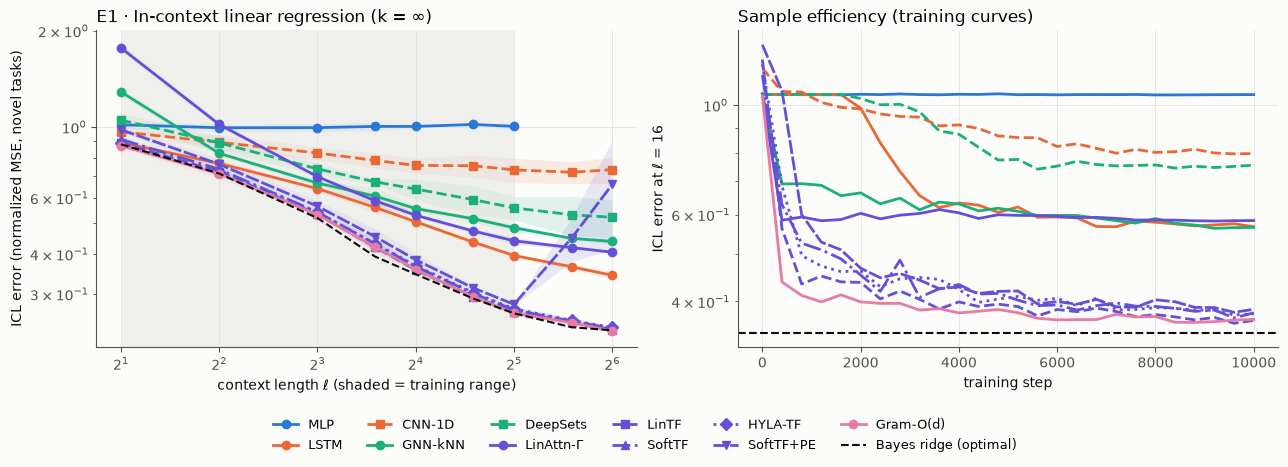

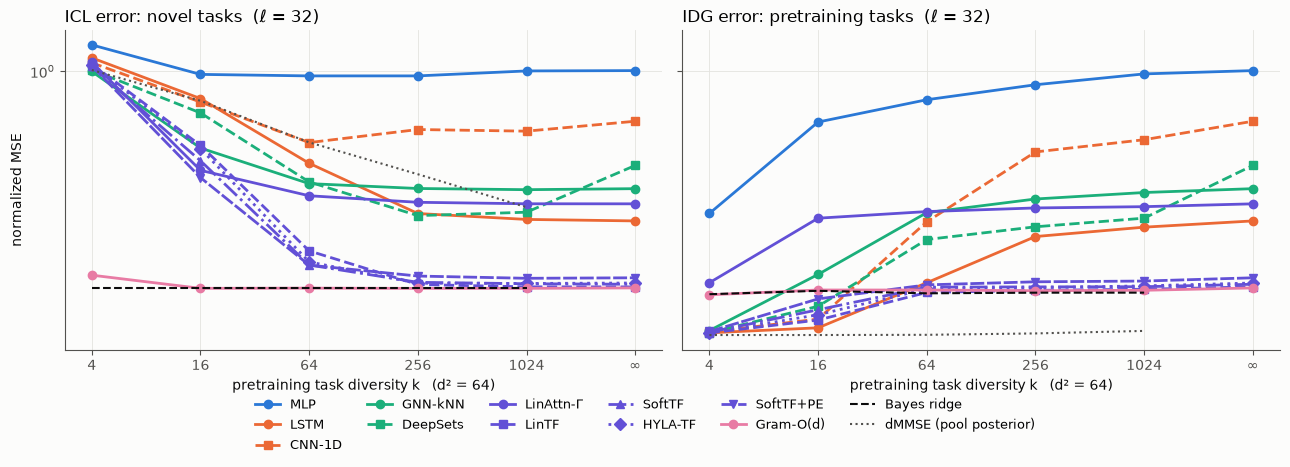

In [8]:
def agg(vals):
    v = np.array(vals, dtype=float); return np.nanmean(v), (np.nanstd(v) if len(v) > 1 else 0.0)

def legend_below(fig, ax, extra=()):
    h, l = ax.get_legend_handles_labels()
    fig.legend(list(h) + list(extra[0]) if extra else h, list(l) + list(extra[1]) if extra else l,
               loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.02), fontsize=9)

# Figure 1: ICL error vs context length (k = inf) + training curves
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axs[0]
for name in MODEL_NAMES:
    m = [agg([results_lr[(name, None, s)]['icl'][l] for s in CFG['seeds']]) for l in LR_TEST_LENS]
    mu, sd = np.array([a for a, _ in m]), np.array([b for _, b in m])
    ax.plot(LR_TEST_LENS, mu, **style(name)); ax.fill_between(LR_TEST_LENS, mu - sd, mu + sd, color=style(name)['color'], alpha=0.12, lw=0)
ax.plot(LR_TEST_LENS, [base_lr['ridge_icl_curve'][l] for l in LR_TEST_LENS], color=INK, ls='--', lw=1.5, label='Bayes ridge (optimal)')
ax.axvspan(LR_TEST_LENS[0], LR_LMAX, color=GRID, alpha=0.5, lw=0)
ax.set_xscale('log', base=2); ax.set_yscale('log'); ax.set_xlabel('context length ℓ (shaded = training range)')
ax.set_ylabel('ICL error (normalized MSE, novel tasks)'); ax.set_title('E1 · In-context linear regression (k = ∞)', loc='left')
ax = axs[1]
for name in MODEL_NAMES:
    c = results_lr[(name, None, CFG['seeds'][0])]['curve']
    ax.plot([s for s, _ in c], [e for _, e in c], **{**style(name), 'markersize': 0})
ax.axhline(base_lr['ridge_icl_curve'][16], color=INK, ls='--', lw=1.5)
ax.set_yscale('log'); ax.set_xlabel('training step'); ax.set_ylabel('ICL error at ℓ = 16')
ax.set_title('Sample efficiency (training curves)', loc='left')
legend_below(fig, axs[0]); fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig(f'{OUT}/E1_icl_vs_length.png', dpi=150, bbox_inches='tight'); plt.show()

# Figure 2: task diversity (small multiples: ICL vs IDG)
ks = [k for k in CFG['k_list'] if k is not None]
kx = ks + [ks[-1] * 4]; klab = [str(k) for k in ks] + ['∞']
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, key in zip(axs, ['icl', 'idg']):
    for name in MODEL_NAMES:
        ys = []
        for k in CFG['k_list']:
            if key == 'icl': ys.append(agg([results_lr[(name, k, s)]['icl'][LR_LMAX] for s in CFG['seeds']])[0])
            else: ys.append(agg([results_lr[(name, k, s)]['idg'] for s in CFG['seeds']])[0] if k is not None
                            else agg([results_lr[(name, None, s)]['icl'][LR_LMAX] for s in CFG['seeds']])[0])
        ax.plot(kx, ys, **style(name))
    ax.plot(ks, [base_lr[f'ridge_{key}'][k] for k in ks], color=INK, ls='--', lw=1.5, label='Bayes ridge')
    ax.plot(ks, [base_lr[f'dmmse_{key}'][k] for k in ks], color=INK2, ls=':', lw=1.5, label='dMMSE (pool posterior)')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xticks(kx); ax.set_xticklabels(klab); ax.minorticks_off()
    ax.set_xlabel(f'pretraining task diversity k   (d² = {D_LR ** 2})')
    ax.set_title(('ICL error: novel tasks' if key == 'icl' else 'IDG error: pretraining tasks') + f'  (ℓ = {LR_LMAX})', loc='left')
axs[0].set_ylabel('normalized MSE')
legend_below(fig, axs[0]); fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig(f'{OUT}/E2_task_diversity.png', dpi=150, bbox_inches='tight'); plt.show()

## E3: symmetry probes (group actions at test time)
For a transform `g` acting on the context, a model is **𝔊-invariant** if `f(gZ) = ρ(g) f(Z)`. We report
`Δ = E[(f(gZ) − ρ(g) f(Z))²] / Var(y)` (0 = exactly equivariant) and the error after transformation.

| transform | group | true symmetry of linreg? | of fuzzy logic? |
|---|---|---|---|
| `perm` (shuffle context) | Σ_n | yes | yes |
| `roll` (cyclic shift of all tokens, query moves) | ℤ_T ⊂ Σ_{n+1} | yes | yes |
| `rotate` x → Rx, R ∈ O(d) | O(d) | yes | **no** |
| `coordperm` (permute x-coordinates) | S_d ⊂ O(d) | yes | yes (relabels variables) |
| `yflip` y → −y (ρ(g) = −1) | ℤ₂ | yes | no |
| `negvar` x_j → 1 − x_j | ℤ₂ | no | yes (relabels literals) |
| `warp2` (duplicate every token: time dilation) | time warping | ≈ (least squares invariant) | ≈ |

Probes use base length ℓ = ℓ_max/2, so `warp2` stays inside the training range. The ★ marks a model that is exactly invariant/equivariant **by construction**.

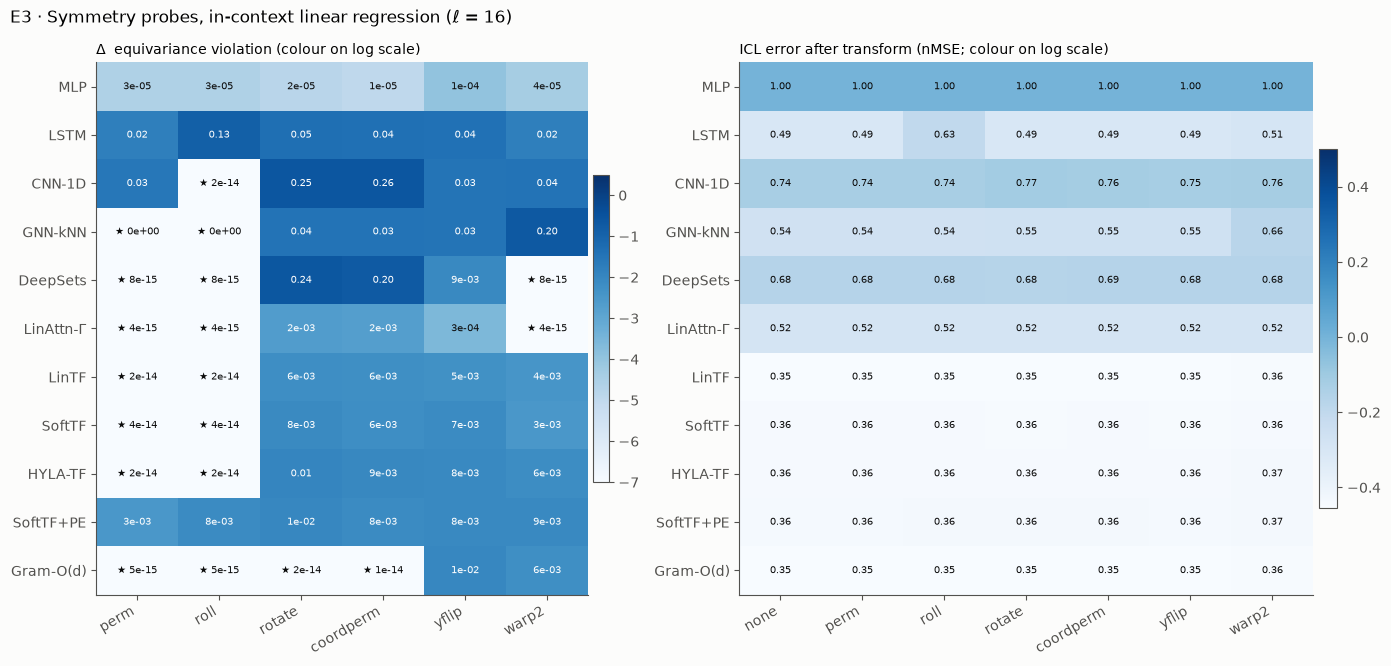

In [9]:
def rand_orth(d, gen):
    q, r = torch.linalg.qr(torch.randn(d, d, generator=gen)); return (q * torch.sign(torch.diagonal(r))).to(DEVICE)

def transform(Z, kind, d, gen):
    B, T, D = Z.shape; Z = Z.clone(); l = T - 1
    if kind == 'perm':
        p = torch.randperm(l, generator=gen).to(DEVICE); Z[:, :l] = Z[:, p]
    elif kind == 'roll':
        Z = torch.roll(Z, shifts=int(torch.randint(1, T, (1,), generator=gen)), dims=1)
    elif kind == 'rotate':
        Z[..., :d] = Z[..., :d] @ rand_orth(d, gen)
    elif kind == 'coordperm':
        Z[..., :d] = Z[..., torch.randperm(d, generator=gen).to(DEVICE)]
    elif kind == 'yflip':
        Z[..., d] = -Z[..., d]
    elif kind == 'negvar':
        j = int(torch.randint(0, d, (1,), generator=gen)); Z[..., j] = 1 - Z[..., j]
    elif kind == 'warp2':
        Z = torch.cat([Z[:, :l].repeat_interleave(2, dim=1), Z[:, l:]], 1)
    return Z

SIGN = {'yflip': -1.0}
BUILT_IN = {  # exact by construction
    'perm':      ['GNN-kNN', 'DeepSets', 'LinAttn-Γ', 'LinTF', 'SoftTF', 'HYLA-TF', 'Gram-O(d)'],
    'roll':      ['CNN-1D', 'GNN-kNN', 'DeepSets', 'LinAttn-Γ', 'LinTF', 'SoftTF', 'HYLA-TF', 'Gram-O(d)'],
    'rotate':    ['Gram-O(d)'], 'coordperm': ['Gram-O(d)'], 'yflip': [], 'negvar': [],
    'warp2':     ['DeepSets', 'LinAttn-Γ'],
}

@torch.no_grad()
def probe(models, task, d, l, kinds, var, seed=0):
    base = fixed_batches(task, l, 'novel' if isinstance(task, LinRegTask) else 'all', CFG['eval_n'], seed)
    out = {}
    for name, model in models.items():
        f0 = predict(model, base['Z'])
        for kind in kinds:
            vals_d, vals_e = [], []
            for rep in range(4):
                gen = torch.Generator().manual_seed(rep)
                fg = predict(model, transform(base['Z'], kind, d, gen))
                s = SIGN.get(kind, 1.0)
                vals_d.append(float(((fg - s * f0) ** 2).mean() / var)); vals_e.append(float(((fg - s * base['yq']) ** 2).mean() / var))
            out[(name, kind)] = (np.mean(vals_d), np.mean(vals_e))
        out[(name, 'none')] = (0.0, float(((f0 - base['yq']) ** 2).mean() / var))
    return out

def plot_probe(res, kinds, title, fname, err_label):
    names = MODEL_NAMES
    M = np.array([[res[(n, k)][0] for k in kinds] for n in names])
    E = np.array([[res[(n, k)][1] for k in ['none'] + kinds] for n in names])
    fig, axs = plt.subplots(1, 2, figsize=(14, 0.45 * len(names) + 1.8), gridspec_kw={'width_ratios': [len(kinds), len(kinds) + 1]})
    for ax, A, cols, lab in [(axs[0], M, kinds, 'Δ  equivariance violation (colour on log scale)'), (axs[1], E, ['none'] + kinds, err_label)]:
        L = np.log10(np.clip(A, 1e-7, None))
        im = ax.imshow(L, cmap='Blues', aspect='auto', vmin=-7 if ax is axs[0] else np.nanmin(L), vmax=max(0.5, np.nanmax(L)))
        ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=30, ha='right')
        ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.grid(False)
        for i, n in enumerate(names):
            for j, c in enumerate(cols):
                v = A[i, j]; txt = 'n/a' if not np.isfinite(v) else (f'{v:.0e}' if v < 1e-2 else f'{v:.2f}')
                if ax is axs[0] and n in BUILT_IN.get(c, []): txt = '★ ' + txt
                ax.text(j, i, txt, ha='center', va='center', fontsize=7.5,
                        color='white' if np.isfinite(L[i, j]) and L[i, j] > (im.norm.vmin + im.norm.vmax) / 2 else INK)
        ax.set_title(lab, loc='left', fontsize=10); fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01)
    fig.suptitle(title, x=0.01, ha='left', fontsize=12); fig.tight_layout()
    fig.savefig(f'{OUT}/{fname}', dpi=150, bbox_inches='tight'); plt.show()

KINDS_LR = ['perm', 'roll', 'rotate', 'coordperm', 'yflip', 'warp2']
probe_lr = probe({n: models_lr_inf[(n, CFG['seeds'][0])] for n in MODEL_NAMES}, LinRegTask(k=None), D_LR, LR_LMAX // 2, KINDS_LR, VAR_LR)
plot_probe(probe_lr, KINDS_LR, f'E3 · Symmetry probes, in-context linear regression (ℓ = {LR_LMAX // 2})', 'E3_probes_linreg.png',
           'ICL error after transform (nMSE; colour on log scale)')

## E4: symmetry mismatch, a drifting task (order matters)
`w_t` interpolates linearly from `w_a` to `w_b` across the context, and the query uses `w_b`. Information about *when* an example occurred is essential, so a Σ_n-invariant model can at best behave like order-agnostic ridge. Baselines: **ridge (order-agnostic)** and a **Bayes oracle** that knows the drift model.

[seed 0] drift MLP         err=1.000 (18s)
[seed 0] drift LSTM        err=0.595 (406s)
[seed 0] drift CNN-1D      err=0.836 (1781s)
[seed 0] drift GNN-kNN     err=0.790 (599s)
[seed 0] drift DeepSets    err=0.926 (59s)
[seed 0] drift LinAttn-Γ   err=0.737 (8s)
[seed 0] drift LinTF       err=0.681 (280s)
[seed 0] drift SoftTF      err=0.689 (211s)
[seed 0] drift HYLA-TF     err=0.688 (742s)
[seed 0] drift SoftTF+PE   err=0.473 (210s)
[seed 0] drift Gram-O(d)   err=0.677 (346s)
[seed 1] drift MLP         err=1.000 (21s)
[seed 1] drift LSTM        err=0.586 (410s)
[seed 1] drift CNN-1D      err=0.835 (1785s)
[seed 1] drift GNN-kNN     err=0.818 (598s)
[seed 1] drift DeepSets    err=0.925 (57s)
[seed 1] drift LinAttn-Γ   err=0.741 (8s)
[seed 1] drift LinTF       err=0.700 (285s)
[seed 1] drift SoftTF      err=0.703 (211s)
[seed 1] drift HYLA-TF     err=0.703 (767s)
[seed 1] drift SoftTF+PE   err=0.496 (221s)
[seed 1] drift Gram-O(d)   err=0.696 (373s)
[seed 2] drift MLP         err=1.000 (

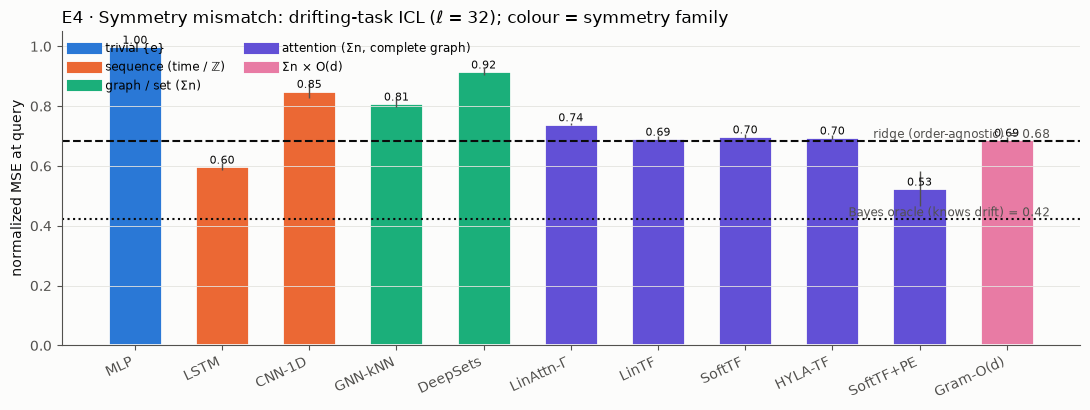

In [10]:
results_dr = {}
dtask = DriftTask()
for seed in CFG['seeds']:
    ev = fixed_batches(dtask, DR_TEST_L, 'train', CFG['eval_n'], seed)
    for name in MODEL_NAMES:
        ts = time.time()
        model, _ = train_model(name, dtask, D_LR, DR_LMIN, DR_LMAX, seed)
        results_dr[(name, seed)] = nmse(predict(model, ev['Z']), ev['yq'], ev['yq'].var())
        print(f'[seed {seed}] drift {name:11s} err={results_dr[(name, seed)]:.3f} ({time.time() - ts:.0f}s)')
evb = fixed_batches(dtask, DR_TEST_L, 'train', CFG['eval_n'], 0)
base_dr = {'ridge (order-agnostic)': nmse(ridge_pred(evb), evb['yq'], evb['yq'].var()),
           'Bayes oracle (knows drift)': nmse(drift_oracle_pred(evb), evb['yq'], evb['yq'].var())}

fig, ax = plt.subplots(figsize=(11, 4.2))
mus = [agg([results_dr[(n, s)] for s in CFG['seeds']]) for n in MODEL_NAMES]
ax.bar(range(len(MODEL_NAMES)), [m for m, _ in mus], yerr=[s for _, s in mus], width=0.62,
       color=[FAM_COLOR[FAMILY[n]] for n in MODEL_NAMES], edgecolor='#fcfcfb', linewidth=2, error_kw=dict(ecolor=INK2, lw=1))
for i, (m, _) in enumerate(mus): ax.text(i, m, f'{m:.2f}', ha='center', va='bottom', fontsize=8, color=INK)
for (lab, v), ls in zip(base_dr.items(), ['--', ':']):
    ax.axhline(v, color=INK, ls=ls, lw=1.5); ax.text(len(MODEL_NAMES) - 0.5, v, f' {lab} = {v:.2f}', va='bottom', ha='right', fontsize=8.5, color=INK2)
ax.set_xticks(range(len(MODEL_NAMES))); ax.set_xticklabels(MODEL_NAMES, rotation=25, ha='right'); ax.grid(axis='x', visible=False)
ax.set_ylabel('normalized MSE at query'); ax.set_title(f'E4 · Symmetry mismatch: drifting-task ICL (ℓ = {DR_TEST_L}); colour = symmetry family', loc='left')
fam_handles = [Line2D([], [], color=c, lw=8) for c in FAM_COLOR.values()]
ax.legend(fam_handles, list(FAM_COLOR.keys()), loc='upper left', fontsize=8.5, ncol=2)
fig.tight_layout(); fig.savefig(f'{OUT}/E4_drift_mismatch.png', dpi=150, bbox_inches='tight'); plt.show()

## E5: compositional ICL on fuzzy logic (Schug et al.)
Each task is a DNF of K=2 terms over L=4 fuzzy variables (Zadeh min/max/1−x). A fraction of the C(16,2)=120 term *combinations* is held out from pretraining (**OOD**), while all terms are seen. Metric: R² on the query. Baselines: Bayesian posterior over **all** 120 functions (knows the compositional family) and over **train-only** functions (memorization).

In [11]:
results_fz = {}; models_fz = {}
for seed in CFG['seeds']:
    for ho in CFG['fuzzy_holdout']:
        ftask = FuzzyTask(holdout=ho, seed=seed)
        ev_ood = {l: fixed_batches(ftask, l, 'ood', CFG['eval_n'], seed) for l in FZ_TEST_LENS}
        ev_iid = fixed_batches(ftask, FZ_LMAX, 'train', CFG['eval_n'], seed)
        for name in MODEL_NAMES:
            ts = time.time()
            model, _ = train_model(name, ftask, FZ_L, FZ_LMIN, FZ_LMAX, seed)
            r = {'ood': {l: r2(predict(model, ev_ood[l]['Z']), ev_ood[l]['yq']) for l in FZ_TEST_LENS},
                 'iid': r2(predict(model, ev_iid['Z']), ev_iid['yq'])}
            results_fz[(name, ho, seed)] = r
            if ho == CFG['fuzzy_holdout'][0] and seed == CFG['seeds'][0]: models_fz[name] = model
            print(f'[seed {seed}] holdout={ho:.1f} {name:11s} OOD R²@{FZ_LMAX}={r["ood"][FZ_LMAX]:.3f} IID R²={r["iid"]:.3f} ({time.time() - ts:.0f}s)')
base_fz = {}
for ho in CFG['fuzzy_holdout']:
    ftask = FuzzyTask(holdout=ho, seed=CFG['seeds'][0])
    b = fixed_batches(ftask, FZ_LMAX, 'ood', min(CFG['eval_n'], 1024), 0)
    base_fz[ho] = {w: r2(fuzzy_bayes_pred(b, ftask, w), b['yq']) for w in ['all', 'train']}

[seed 0] holdout=0.1 MLP         OOD R²@32=0.076 IID R²=0.090 (15s)
[seed 0] holdout=0.1 LSTM        OOD R²@32=0.707 IID R²=0.725 (303s)
[seed 0] holdout=0.1 CNN-1D      OOD R²@32=0.655 IID R²=0.650 (1743s)
[seed 0] holdout=0.1 GNN-kNN     OOD R²@32=0.913 IID R²=0.909 (475s)
[seed 0] holdout=0.1 DeepSets    OOD R²@32=0.503 IID R²=0.479 (47s)
[seed 0] holdout=0.1 LinAttn-Γ   OOD R²@32=0.015 IID R²=-0.012 (6s)
[seed 0] holdout=0.1 LinTF       OOD R²@32=0.910 IID R²=0.902 (217s)
[seed 0] holdout=0.1 SoftTF      OOD R²@32=0.954 IID R²=0.951 (178s)
[seed 0] holdout=0.1 HYLA-TF     OOD R²@32=0.944 IID R²=0.944 (530s)
[seed 0] holdout=0.1 SoftTF+PE   OOD R²@32=0.830 IID R²=0.838 (159s)
[seed 0] holdout=0.1 Gram-O(d)   OOD R²@32=0.789 IID R²=0.800 (273s)
[seed 0] holdout=0.3 MLP         OOD R²@32=0.055 IID R²=0.088 (15s)
[seed 0] holdout=0.3 LSTM        OOD R²@32=0.568 IID R²=0.748 (303s)
[seed 0] holdout=0.3 CNN-1D      OOD R²@32=0.562 IID R²=0.673 (1751s)
[seed 0] holdout=0.3 GNN-kNN     OOD

/Users/asataryd/Documents/ENI-Projects/Aslan/NeuroAILab/Githubs/ICL-Symmetry-Groups-Benchmark/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


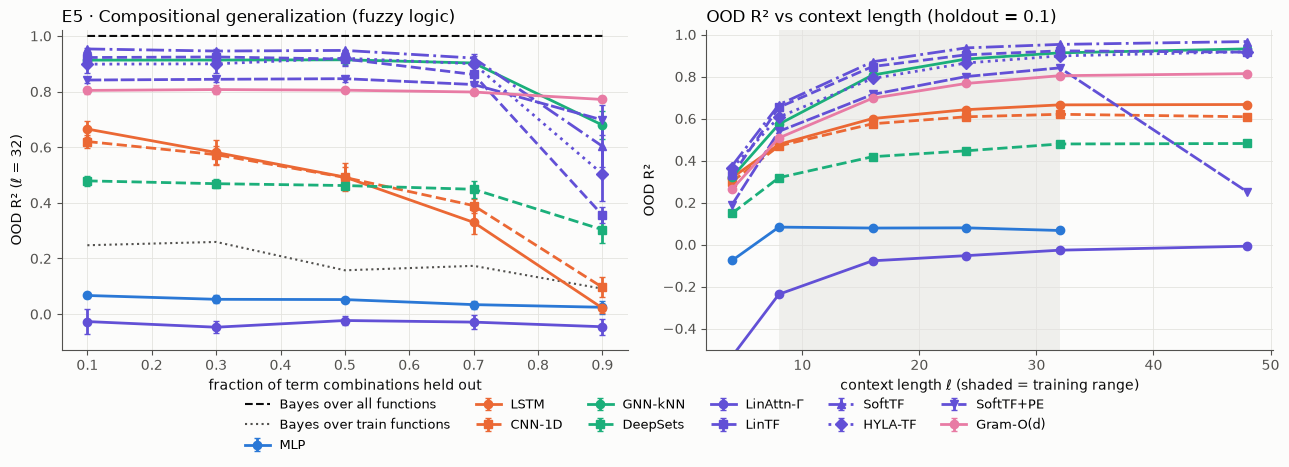

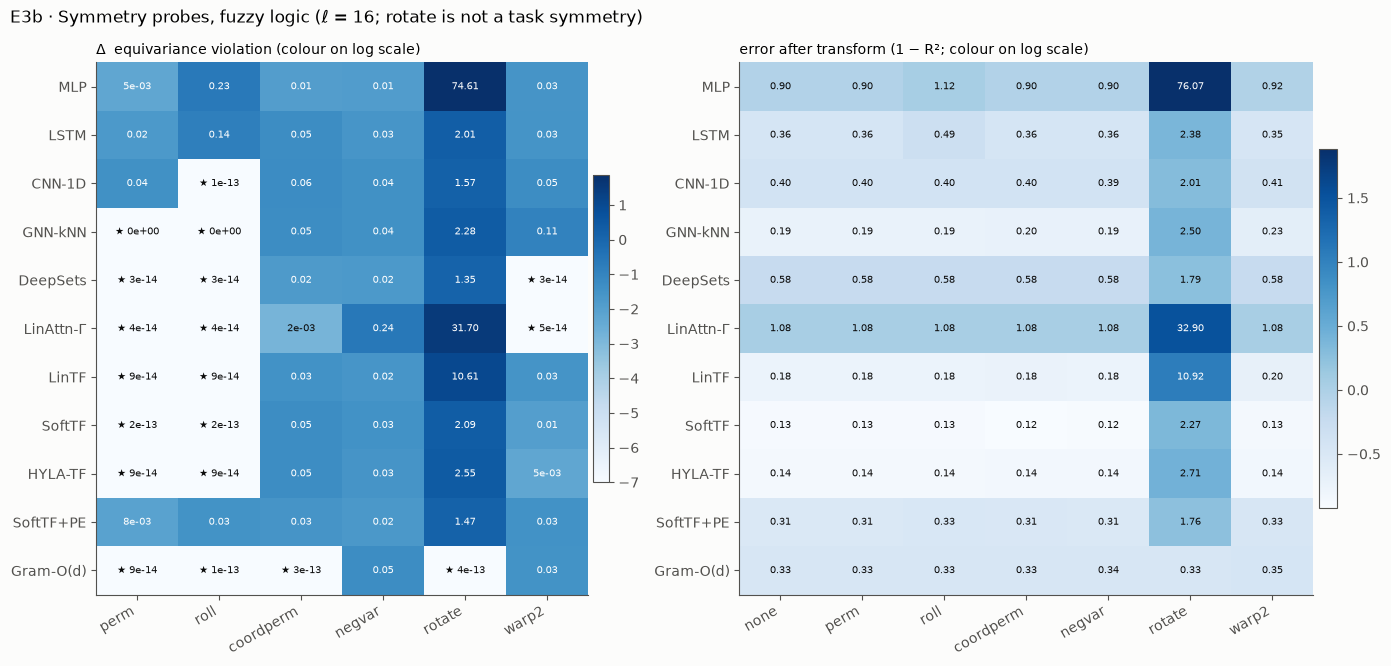

In [12]:
ho_list = CFG['fuzzy_holdout']
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axs[0]
for name in MODEL_NAMES:
    m = [agg([results_fz[(name, ho, s)]['ood'][FZ_LMAX] for s in CFG['seeds']]) for ho in ho_list]
    ax.errorbar(ho_list, [a for a, _ in m], yerr=[b for _, b in m], capsize=2, **style(name))
ax.plot(ho_list, [base_fz[h]['all'] for h in ho_list], color=INK, ls='--', lw=1.5, label='Bayes over all functions')
ax.plot(ho_list, [base_fz[h]['train'] for h in ho_list], color=INK2, ls=':', lw=1.5, label='Bayes over train functions')
ax.set_xlabel('fraction of term combinations held out'); ax.set_ylabel(f'OOD R² (ℓ = {FZ_LMAX})')
ax.set_ylim(max(-0.5, ax.get_ylim()[0]), 1.02); ax.set_title('E5 · Compositional generalization (fuzzy logic)', loc='left')
ax = axs[1]; ho0 = ho_list[0]
for name in MODEL_NAMES:
    ys = [agg([results_fz[(name, ho0, s)]['ood'][l] for s in CFG['seeds']])[0] for l in FZ_TEST_LENS]
    ax.plot(FZ_TEST_LENS, ys, **{**style(name), 'label': None})
ax.axvspan(FZ_LMIN, FZ_LMAX, color=GRID, alpha=0.5, lw=0)
ax.set_xlabel('context length ℓ (shaded = training range)'); ax.set_ylabel('OOD R²'); ax.set_ylim(max(-0.5, ax.get_ylim()[0]), 1.02)
ax.set_title(f'OOD R² vs context length (holdout = {ho0})', loc='left')
legend_below(fig, axs[0]); fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig(f'{OUT}/E5_fuzzy_compositional.png', dpi=150, bbox_inches='tight'); plt.show()

# Symmetry probes on fuzzy-logic models (rotation is NOT a task symmetry here)
KINDS_FZ = ['perm', 'roll', 'coordperm', 'negvar', 'rotate', 'warp2']
ftask0 = FuzzyTask(holdout=ho_list[0], seed=CFG['seeds'][0])
yv = float(fixed_batches(ftask0, FZ_LMAX // 2, 'all', CFG['eval_n'], 0)['yq'].var())
probe_fz = probe(models_fz, ftask0, FZ_L, FZ_LMAX // 2, KINDS_FZ, yv)
plot_probe(probe_fz, KINDS_FZ, f'E3b · Symmetry probes, fuzzy logic (ℓ = {FZ_LMAX // 2}; rotate is not a task symmetry)',
           'E3b_probes_fuzzy.png', 'error after transform (1 − R²; colour on log scale)')

## Summary table and saved results

In [13]:
rows = []
for n in MODEL_NAMES:
    s0 = CFG['seeds']
    row = {'model': n, 'family': FAMILY[n],
           'params': sum(p.numel() for p in models_lr_inf[(n, s0[0])].parameters()),
           f'ICL@{LR_LMAX}': agg([results_lr[(n, None, s)]['icl'][LR_LMAX] for s in s0])[0],
           'ICL@64 (extrap.)': agg([results_lr[(n, None, s)]['icl'][64] for s in s0])[0],
           f'IDG k={ks[0]}': agg([results_lr[(n, ks[0], s)]['idg'] for s in s0])[0],
           f'ICL k={ks[0]}': agg([results_lr[(n, ks[0], s)]['icl'][LR_LMAX] for s in s0])[0],
           'Δperm': probe_lr[(n, 'perm')][0], 'Δrotate': probe_lr[(n, 'rotate')][0],
           'drift err': agg([results_dr[(n, s)] for s in s0])[0]}
    for ho in ho_list:
        row[f'fuzzy OOD R² ho={ho}'] = agg([results_fz[(n, ho, s)]['ood'][FZ_LMAX] for s in s0])[0]
    rows.append(row)
try:
    import pandas as pd
    df = pd.DataFrame(rows).set_index('model')
    df.to_csv(f'{OUT}/summary.csv')
    display(df.style.format(precision=3).background_gradient(cmap='Blues_r', subset=[c for c in df.columns if 'ICL' in c or 'IDG' in c or 'drift' in c])
            .background_gradient(cmap='Blues', subset=[c for c in df.columns if 'R²' in c]))
except Exception as e:
    print(e); [print(r) for r in rows]
print('Baselines:', {'ridge ICL@lmax': base_lr['ridge_icl_curve'][LR_LMAX], **base_dr,
                     **{f'fuzzy Bayes ho={h}': v for h, v in base_fz.items()}})

def _ser(d): return {str(k): v for k, v in d.items()}
json.dump({'config': {**CFG, 'MODE': MODE, 'd': D_LR, 'rho': RHO}, 'linreg': _ser(results_lr), 'baselines_linreg': {k: _ser(v) for k, v in base_lr.items()},
           'probe_linreg': _ser(probe_lr), 'drift': _ser(results_dr), 'baselines_drift': base_dr, 'fuzzy': _ser(results_fz),
           'baselines_fuzzy': _ser(base_fz), 'probe_fuzzy': _ser(probe_fz)}, open(f'{OUT}/all_results.json', 'w', encoding='utf-8'), default=str, indent=1)
print('saved to', OUT, os.listdir(OUT))

/Users/asataryd/Documents/ENI-Projects/Aslan/NeuroAILab/Githubs/ICL-Symmetry-Groups-Benchmark/.venv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


,family,params,ICL@32,ICL@64 (extrap.),IDG k=4,ICL k=4,Δperm,Δrotate,drift err,fuzzy OOD R² ho=0.1,fuzzy OOD R² ho=0.3,fuzzy OOD R² ho=0.5,fuzzy OOD R² ho=0.7,fuzzy OOD R² ho=0.9
model,,,,,,,,,,,,,,
MLP,trivial {e},159233,1.004,nan,0.415,1.177,0.000,0.000,1.000,0.067,0.053,0.052,0.034,0.025
LSTM,sequence (time / ℤ),265729,0.396,0.343,0.198,1.086,0.015,0.047,0.599,0.665,0.581,0.493,0.330,0.022
CNN-1D,sequence (time / ℤ),133889,0.734,0.735,0.199,1.054,0.027,0.254,0.852,0.620,0.573,0.491,0.390,0.096
GNN-kNN,graph / set (Σn),77185,0.483,0.438,0.201,0.998,0.000,0.036,0.810,0.913,0.913,0.914,0.903,0.680
DeepSets,graph / set (Σn),68481,0.558,0.521,0.198,1.008,0.000,0.241,0.917,0.479,0.469,0.462,0.449,0.304
LinAttn-Γ,"attention (Σn, complete graph)",72,0.440,0.405,0.270,1.057,0.000,0.002,0.741,-0.027,-0.047,-0.023,-0.029,-0.045
LinTF,"attention (Σn, complete graph)",101313,0.263,0.232,0.198,1.045,0.000,0.006,0.692,0.922,0.924,0.917,0.862,0.356
SoftTF,"attention (Σn, complete graph)",101313,0.267,0.234,0.199,1.030,0.000,0.008,0.700,0.953,0.946,0.948,0.921,0.603
HYLA-TF,"attention (Σn, complete graph)",101313,0.269,0.236,0.198,1.039,0.000,0.011,0.696,0.899,0.900,0.920,0.900,0.504


Baselines: {'ridge ICL@lmax': 0.2609788775444031, 'ridge (order-agnostic)': 0.6835168600082397, 'Bayes oracle (knows drift)': 0.4217067062854767, 'fuzzy Bayes ho=0.1': {'all': 0.9999843835830688, 'train': 0.24762225151062012}, 'fuzzy Bayes ho=0.3': {'all': 0.9999998807907104, 'train': 0.2594534754753113}, 'fuzzy Bayes ho=0.5': {'all': 1.0, 'train': 0.15756285190582275}, 'fuzzy Bayes ho=0.7': {'all': 0.9999160766601562, 'train': 0.17349672317504883}, 'fuzzy Bayes ho=0.9': {'all': 0.9999998807907104, 'train': 0.09141218662261963}}
saved to results ['E3_probes_linreg.png', 'summary.csv', 'E2_task_diversity.png', 'E5_fuzzy_compositional.png', 'E1_icl_vs_length.png', 'E3b_probes_fuzzy.png', 'E4_drift_mismatch.png', 'all_results.json']


## How to read the results (what each comparison tests)
* **Equivariance by construction vs learned.** Rows marked ★ in E3 must show Δ ≈ 0 (up to float error). This sanity-checks the implementations. Non-★ entries show how much symmetry a model **learned from data alone** (for example, how close `SoftTF+PE` or `LSTM` come to permutation invariance after pretraining on i.i.d. contexts).
* **Symmetry ↔ sample efficiency.** Compare the training curves in E1: models whose group matches the task (Σ_n, and Σ_n × O(d) for linreg) should reach ridge-level ICL with fewer steps.
* **Symmetry ↔ length generalization.** Mean-normalized Σ_n models (`DeepSets`, `LinAttn-Γ`, `Gram-O(d)`, linear/HYLA attention) can be evaluated at ℓ > ℓ_max. `MLP` cannot (n/a), and order-based models (`LSTM`, `CNN`, `+PE`) usually degrade.
* **Task diversity (Lu et al.).** At small k the IDG error approaches dMMSE (memorization) and the ICL error is high. As k passes about d², the ICL error approaches ridge. Check whether stronger symmetry (e.g. O(d)) **shifts the transition to smaller k**: an O(d)-invariant model cannot memorize individual `w` vectors in a rotation-dependent way.
* **Mismatch (E4, and `rotate` on fuzzy).** The same symmetry that helps in E1 caps performance when the task breaks it. Σ_n models should sit near order-agnostic ridge in E4, while order-aware models can approach the oracle.
* **Compositionality (E5).** Compare HYLA vs softmax vs linear attention (Schug et al.'s claim) against set/graph/sequence models, and the locality bias of `GNN-kNN` on a piecewise nonlinear task vs on linear regression.

* **Loss plateaus.** ICL regression has a long initial plateau at error ≈ 1 (predicting the mean). How long a model sits there depends on its inductive bias, and that is a result in itself. Still, check the E1 training curves before concluding that a model *cannot* do ICL: in our tests `LSTM` and `DeepSets` only started escaping after about 2k steps, and the flattened `MLP` did not escape within 4k.

*Tips:* use `MODE='FULL'` for 3 seeds and longer training before drawing conclusions. All hyperparameters (width, depth, ℓ ranges, d, ρ) are at the top. Models can be removed from `MODEL_NAMES` to save time.